# General Data Science Track — Day 1: Data wrangling and cleaning

**Estimated core time:** 60 minutes  
**Curriculum:** Phase 1.1 — Python, data wrangling, and data quality

## Why this matters

Most data-science failures begin before a model is fitted: the analyst misunderstands what one row represents, silently multiplies rows in a join, treats unknown values as zeros, or reports a transaction-level pattern as if it were a customer-level pattern. In this session you will turn two related raw tables into a validated customer-level analysis and communicate one appropriately limited finding.

## Learning objectives

By the end of the session, you will be able to:

- audit shapes, types, missingness, key uniqueness, and row granularity;
- clean dates and missing values while preserving information about what was missing;
- create vectorized features and customer-level summaries with pandas;
- join tables with an explicit cardinality check and validate the result; and
- create a plotnine comparison and state what the descriptive analysis does—and does not—show.

## R-to-Python bridge

| tidyverse | pandas |
|---|---|
| `read_csv()` | `pd.read_csv()` |
| `glimpse()` | `.info()`, `.head()`, `.dtypes` |
| `mutate()` | assignment or `.assign()` |
| `group_by() |> summarise()` | `.groupby().agg()` |
| `left_join()` | `.merge(how="left", validate=...)` |
| `is.na()` | `.isna()` |

A pandas `DataFrame` has both columns and an index. Unless the index has been deliberately designed as a key, treat it as row labels—not as an analysis variable.

## Scenario and data grain

You have been asked: **How does customer value vary across segments, regions, and marketing opt-in status?**

- `data/customers.csv`: one intended row per customer; key `customer_id`.
- `data/transactions.csv`: one intended row per transaction; key `transaction_id`; many transactions may belong to one customer.
- Monetary columns are in euros. `discount_pct` is a percentage from 0 to 100.
- A returned transaction will count as negative revenue in this exercise.
- The fixed analysis date is `2025-12-31`, so results do not change depending on when the notebook is run.

The data are synthetic. Your conclusions are practice findings, not claims about a real population.

## Suggested pacing

- Load and audit: 10 minutes
- Clean and engineer features: 17 minutes
- Aggregate, join, and validate: 16 minutes
- Visualize and communicate: 12 minutes
- Retrieval practice: 5 minutes

If one task runs long, leave the optional extension for later.

## Task 1 — Load the two tables and establish their grain (5 minutes)

Import pandas as `pd` and the plotnine objects you expect to need later. Load both CSV files into `customers` and `transactions`. Display the first few rows, shapes, and dtypes.

Before running the cell, predict:

1. Which columns will pandas probably read as generic strings even though they have richer meaning?
2. Which table should have more rows, and why?

Self-check: the raw shapes should be `(2000, 6)` and `(12091, 7)`. In one sentence, state what one row represents in each table.

In [1]:
import pandas as pd
import numpy as np
from plotnine import *


1. Date is formated as string, while it contains datetime information, this likely needs to be transformed later on.
2. transactions is probably larger than customer, as transaction probably contains more rows of the same customer


Customer contains one row per customer, transaction contains one row per transaction.

In [11]:
# Load the two tables
transactions = pd.read_csv("data/transactions.csv")
customers = pd.read_csv("data/customers.csv")

print(transactions.shape)
print(customers.shape)

print(transactions.dtypes)
print(customers.dtypes)


(12091, 7)
(2000, 6)
transaction_id          str
customer_id             str
transaction_date        str
category                str
amount_eur          float64
discount_pct        float64
returned               bool
dtype: object
customer_id             str
age                 float64
region                  str
segment                 str
signup_date             str
marketing_opt_in       bool
dtype: object


In [9]:
transactions.head()

,transaction_id,customer_id,transaction_date,category,amount_eur,discount_pct,returned
0,T000001,C00001,2025-03-23,hardware,118.37,0.0,False
1,T000002,C00001,2024-08-22,software,78.01,0.0,False
2,T000003,C00001,2025-11-23,training,103.17,0.0,False
3,T000004,C00001,2024-10-29,software,79.45,0.0,False
4,T000005,C00001,2025-06-30,software,249.17,0.0,False


In [10]:
customers.head()

,customer_id,age,region,segment,signup_date,marketing_opt_in
0,C00001,33.0,east,consumer,2020-06-11,False
1,C00002,56.0,east,small_business,2023-11-13,True
2,C00003,43.0,north,consumer,2023-04-09,False
3,C00004,39.0,north,small_business,2022-03-11,False
4,C00005,42.0,east,small_business,2022-03-01,False


## Task 2 — Run a compact data-quality audit (5 minutes)

For both tables, calculate or inspect:

- duplicate counts for the intended primary key;
- missing counts **and percentages** by column;
- unique values for `region`, `segment`, and `category`; and
- minimum and maximum of the monetary and discount columns.

Also count transaction `customer_id` values that do not occur in `customers`. Do not clean anything yet. Summarize the two quality issues that require a decision.

Useful patterns:

```python
df[key].duplicated().sum()
df.isna().mean().mul(100).sort_values(ascending=False)
child_key.isin(parent_key)
```

In [16]:
# check if there are duplicate customer id's in customer data
print(customers['customer_id'].duplicated().sum())


# check if there are duplicate transaction id's in transaction data
print(transactions['transaction_id'].duplicated().sum())


0
0


In [19]:
customers.shape

(2000, 6)

2000

In [24]:
# count missing values per column
print(customers.isna().sum())

# how much percentage of values is missing per row
print(customers.isna().sum() / len(customers) * 100)

customer_id          0
age                 55
region               0
segment              0
signup_date          0
marketing_opt_in     0
dtype: int64
customer_id         0.00
age                 2.75
region              0.00
segment             0.00
signup_date         0.00
marketing_opt_in    0.00
dtype: float64


In [25]:
# count missing values per column
print(transactions.isna().sum())

# how much percentage of values is missing per row
print(transactions.isna().sum() / len(transactions) * 100)

transaction_id        0
customer_id           0
transaction_date      0
category              0
amount_eur            0
discount_pct        231
returned              0
dtype: int64
transaction_id      0.000000
customer_id         0.000000
transaction_date    0.000000
category            0.000000
amount_eur          0.000000
discount_pct        1.910512
returned            0.000000
dtype: float64


In [26]:
# what are unique values per region

customers['region'].unique()

<StringArray>
['east', 'north', 'south', 'west']
Length: 4, dtype: str

In [27]:
# what are unique values per segment

customers['segment'].unique()

<StringArray>
['consumer', 'small_business', 'enterprise']
Length: 3, dtype: str

In [28]:
# what are unique values per category

transactions['category'].unique()

<StringArray>
['hardware', 'software', 'training', 'services']
Length: 4, dtype: str

In [32]:
# minimum and maximum of the monetary and discount columns.
print(transactions['amount_eur'].min())
print(transactions['amount_eur'].max())
print(transactions['discount_pct'].min())
print(transactions['discount_pct'].max())

3.5
5417.36
0.0
20.0


## Task 3 — Make types explicit and validate them (5 minutes)

Create `.copy()` versions named `customers_clean` and `transactions_clean`; leave the raw objects unchanged. Convert both date columns with `pd.to_datetime(..., errors="raise")`. Convert `region`, `segment`, and `category` to the pandas `category` dtype.

Before running, predict the Python/pandas type returned by this expression after conversion:

```python
transactions_clean["transaction_date"].dt.year
```

Add assertions that both date columns have a datetime dtype and both original DataFrames still have their original dtypes. Why is `errors="raise"` useful during a cleaning audit?

code prediction: "transactions_clean["transaction_date"].dt.year" will give a string with just the year.


In [49]:
customers_clean = customers.copy()
transaction_clean = transactions.copy() 

# Cleanup Date
customers_clean['signup_date'] = pd.to_datetime(customers_clean['signup_date'])
transaction_clean['transaction_date'] = pd.to_datetime(transaction_clean['transaction_date'])

# Cleanup region, make it a category
customers_clean['region'] = pd.Categorical(customers_clean['region'])

# Cleanup segment, make it a category
customers_clean['segment'] = pd.Categorical(customers_clean['segment'])

# Cleanup Category, make it a category
transaction_clean['category'] = pd.Categorical(transaction_clean['category'])


print(customers_clean.dtypes)
print(transaction_clean.dtypes)

customer_id                    str
age                        float64
region                    category
segment                   category
signup_date         datetime64[us]
marketing_opt_in              bool
dtype: object
transaction_id                 str
customer_id                    str
transaction_date    datetime64[us]
category                  category
amount_eur                 float64
discount_pct               float64
returned                      bool
dtype: object


## Task 4 — Handle missing values without erasing their history (7 minutes)

Use these explicit analysis assumptions:

- For missing customer ages, retain an `age_missing` Boolean indicator, then fill age with the median within `segment`.
- For missing discounts, retain a `discount_missing` Boolean indicator, then fill the discount with the median within `category`.
- If a group median were missing, use the overall median as a fallback.

Use `.groupby(...)[...].transform("median")` so the imputed values align with the original rows. Verify that the two cleaned columns contain no missing values and that the indicator sums equal the original missing counts.

These are pragmatic assumptions for an exercise, not universal truths. Write one sentence naming a plausible alternative interpretation of a missing discount.

In [71]:
customers_clean['age_missing'] = customers_clean['age'].isna()
transaction_clean['discount_missing'] = transaction_clean['discount_pct'].isna()

# Fill in customer medians
age_medians = customers_clean.groupby("segment")["age"].transform("median")
customers_clean['age'] =customers_clean['age'].fillna(age_medians)

# Fill in missing discounts
discount_medians  = transaction_clean.groupby("category")["discount_pct"].transform("median")
transaction_clean['discount_pct'] = transaction_clean['discount_pct'].fillna(discount_medians)


In [75]:
transaction_clean.isna().sum()
customers_clean.isna().sum()

customer_id         0
age                 0
region              0
segment             0
signup_date         0
marketing_opt_in    0
age_missing         0
dtype: int64

## Task 5 — Engineer analysis-ready transaction features (5 minutes)

Add these vectorized columns to `transactions_clean`:

- `net_amount_eur = amount_eur * (1 - discount_pct / 100)`;
- `signed_revenue_eur`, equal to negative `net_amount_eur` for returns and positive otherwise; and
- `transaction_month`, representing the calendar month of the transaction.

Avoid a row-wise loop. You may use `.where()`, `.mask()`, or NumPy's `np.where()` for signed revenue. Check that returned rows are never positive and non-returned rows are never negative.

In a short note, distinguish gross amount, discounted amount, and signed revenue.

In [80]:
transaction_clean['net_amount_eur'] = transaction_clean['amount_eur'] * (1 - transaction_clean['discount_pct'] / 100)
transaction_clean["transaction_month"] = transaction_clean["transaction_date"].dt.to_period("M")
transaction_clean["signed_revenue_eur"] = np.where(transaction_clean["returned"] == True, -transaction_clean["net_amount_eur"], transaction_clean["net_amount_eur"])

## Task 6 — Aggregate transactions to one row per customer (8 minutes)

Build `customer_summary` with named aggregation. It should contain:

- `customer_id`;
- `transaction_count` (unique transaction IDs);
- `gross_amount_eur` (sum of `amount_eur`);
- `net_revenue_eur` (sum of `signed_revenue_eur`);
- `return_rate` (mean of Boolean `returned`);
- `mean_discount_pct`;
- `first_purchase`; and
- `last_purchase`.

Before running, predict the output shape. Then verify `customer_id` is unique and reconcile total `transaction_count` with the number of unique raw transactions.

Named-aggregation reminder:

```python
df.groupby("group", as_index=False).agg(
    new_name=("source_column", "aggregation")
)
```

Shape should be 1 line per customer an column should be the size of all new created columns plus customer id

In [82]:
# First merge both clean data sets
merged = pd.merge(customers_clean, transaction_clean, on="customer_id", how="left")
merged.head()

,customer_id,age,region,segment,signup_date,marketing_opt_in,age_missing,transaction_id,transaction_date,category,amount_eur,discount_pct,returned,discount_missing,net_amount_eur,transaction_month,signed_revenue_eur
0,C00001,33.0,east,consumer,2020-06-11,False,False,T000001,2025-03-23,hardware,118.37,0.0,False,False,118.37,2025-03,118.37
1,C00001,33.0,east,consumer,2020-06-11,False,False,T000002,2024-08-22,software,78.01,0.0,False,False,78.01,2024-08,78.01
2,C00001,33.0,east,consumer,2020-06-11,False,False,T000003,2025-11-23,training,103.17,0.0,False,False,103.17,2025-11,103.17
3,C00001,33.0,east,consumer,2020-06-11,False,False,T000004,2024-10-29,software,79.45,0.0,False,False,79.45,2024-10,79.45
4,C00001,33.0,east,consumer,2020-06-11,False,False,T000005,2025-06-30,software,249.17,0.0,False,False,249.17,2025-06,249.17


In [85]:
customer_summary = merged.groupby("customer_id", as_index=False).agg(
    transaction_count = ("transaction_id", "count"),
    gross_amount_eur = ("amount_eur", "sum"),
    net_revenue_eur = ("signed_revenue_eur", "sum"),
    return_rate = ("returned", "mean"),
    mean_discount_pct = ("discount_pct", "mean"),
    first_purchase = ("transaction_date", "min"),
    last_purchase = ("transaction_date", "max")
)

customer_summary.head()

,customer_id,transaction_count,gross_amount_eur,net_revenue_eur,return_rate,mean_discount_pct,first_purchase,last_purchase
0,C00001,9,1494.35,1452.2300,0.000000,2.222222,2024-07-14,2025-11-23
1,C00002,7,537.87,392.4105,0.142857,0.714286,2024-10-23,2025-11-07
2,C00003,6,751.58,-159.8580,0.333333,6.666667,2024-03-31,2025-06-09
3,C00004,5,634.69,623.7880,0.000000,3.000000,2024-01-17,2025-07-01
4,C00005,4,531.75,443.9580,0.250000,5.000000,2024-04-02,2025-06-18


## Task 7 — Join deliberately, then add customer time features (8 minutes)

First read this broken join and predict the error before running an adapted version:

```python
transactions_clean.merge(
    customers_clean, on="customer_id", validate="one_to_one"
)
```

Explain why its cardinality claim is wrong and what the correct relationship is. Then create `analysis_df` by left-joining `customers_clean` to `customer_summary`. Because both inputs now have one row per customer, use `validate="one_to_one"` and `indicator=True`.

Validate all of the following:

- `analysis_df` has exactly 2,000 rows;
- `customer_id` remains unique;
- every merge indicator is `both`; and
- the sum of transaction counts is unchanged.

Finally, using the fixed timestamp `2025-12-31`, add `customer_tenure_days` from `signup_date` and `purchase_recency_days` from `last_purchase`.

The issue here is the one to one mapping between the customer and transaction data. the one to one argument checks wheather each level of the grouping variable (here customer id) occurs exactly once in each data set. this is wrong, because we know that a single customer can do multiple transactions. 

In [101]:
analysis_df = pd.merge(customer_summary, customers_clean, on="customer_id", how="left", validate="one_to_one", indicator = True)
analysis_df

# Finally, using the fixed timestamp `2025-12-31`, add `customer_tenure_days` from `signup_date` and `purchase_recency_days` from `last_purchase`.
analysis_df["customer_tenure_days"] = (pd.Timestamp("2025-12-31") - analysis_df["signup_date"]).dt.days
analysis_df["purchase_recency_days"] = (pd.Timestamp("2025-12-31") - analysis_df["last_purchase"]).dt.days
analysis_df

,customer_id,transaction_count,gross_amount_eur,net_revenue_eur,return_rate,mean_discount_pct,first_purchase,last_purchase,age,region,segment,signup_date,marketing_opt_in,age_missing,_merge,customer_tenure_days,purchase_recency_days
0,C00001,9,1494.35,1452.2300,0.000000,2.222222,2024-07-14,2025-11-23,33.0,east,consumer,2020-06-11,False,False,both,2029,38
1,C00002,7,537.87,392.4105,0.142857,0.714286,2024-10-23,2025-11-07,56.0,east,small_business,2023-11-13,True,False,both,779,54
2,C00003,6,751.58,-159.8580,0.333333,6.666667,2024-03-31,2025-06-09,43.0,north,consumer,2023-04-09,False,False,both,997,205
3,C00004,5,634.69,623.7880,0.000000,3.000000,2024-01-17,2025-07-01,39.0,north,small_business,2022-03-11,False,False,both,1391,183
4,C00005,4,531.75,443.9580,0.250000,5.000000,2024-04-02,2025-06-18,42.0,east,small_business,2022-03-01,False,False,both,1401,196
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,C01996,5,392.08,357.7175,0.000000,7.000000,2024-03-12,2025-11-05,47.0,north,consumer,2020-01-05,True,False,both,2187,56
1996,C01997,3,334.47,334.4700,0.000000,0.000000,2024-09-29,2025-07-24,33.0,west,consumer,2022-10-05,False,False,both,1183,160
1997,C01998,5,1109.75,225.2095,0.200000,3.000000,2024-02-26,2025-01-08,43.0,north,consumer,2024-12-17,True,False,both,379,357
1998,C01999,5,340.82,198.3440,0.200000,4.000000,2024-06-22,2025-10-16,21.0,east,consumer,2021-05-27,False,False,both,1679,76


## Task 8 — Visualize customer value at the correct grain (7 minutes)

Using `analysis_df`, make a plotnine boxplot of `net_revenue_eur` by `segment`, faceted by `region`. Give it readable axis labels and a title. If a few large values compress the boxes, choose and justify either a transformed y-scale or a coordinated zoom that does not discard data from statistical calculations.

The plot must use one row per customer. Write two observations: one about location or spread and one about a possible outlier/tail pattern. Do not use causal language.

Useful plotnine components include `ggplot`, `aes`, `geom_boxplot`, `facet_wrap`, `labs`, `theme`, and `element_text`.

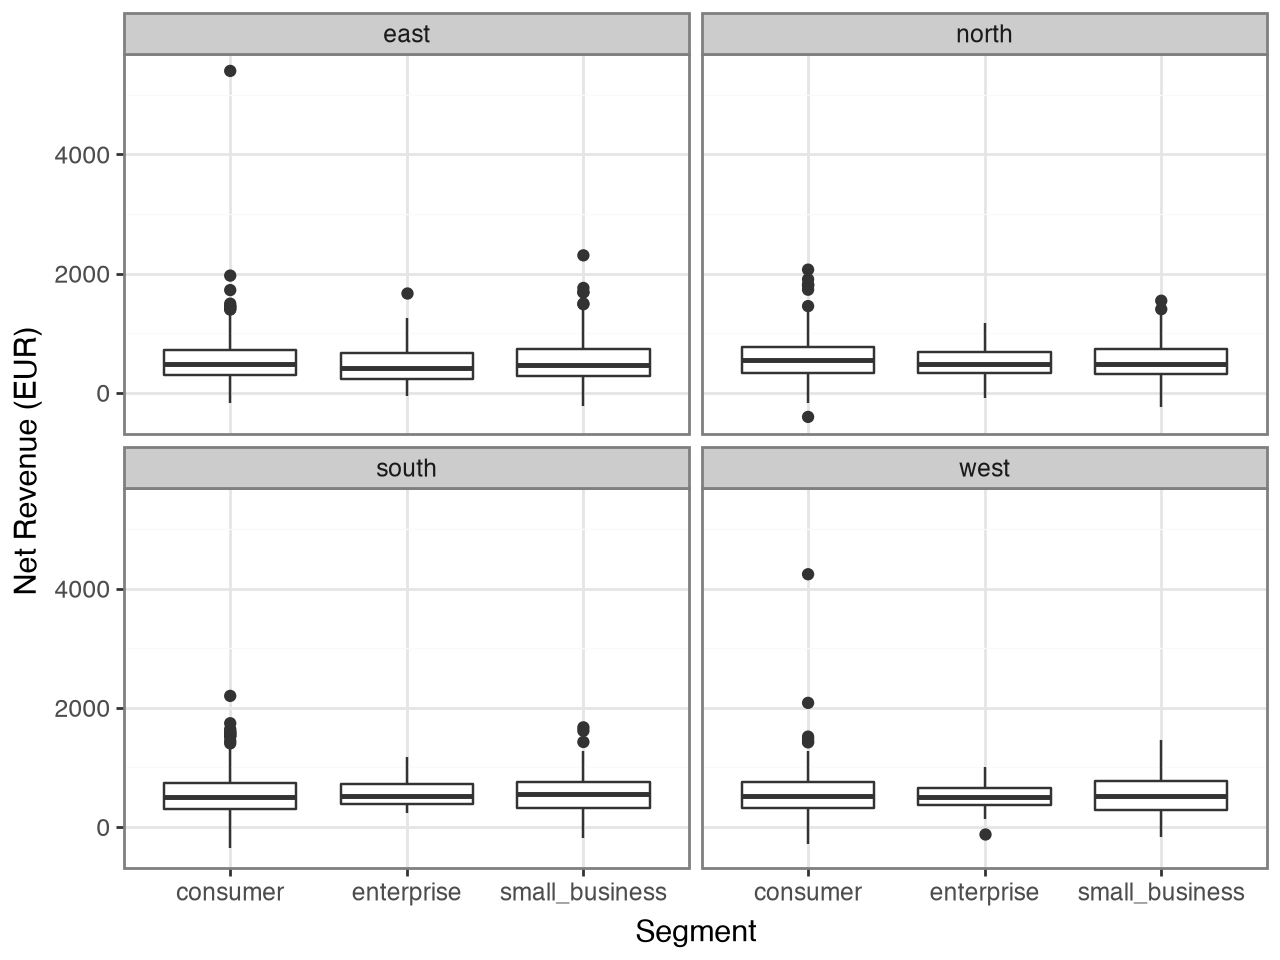

In [108]:
(
    ggplot(analysis_df, aes(y = "net_revenue_eur", x = "segment")) 
    + geom_boxplot()
    + facet_wrap("region")
    + scale_y_continuous(name = "Net Revenue (EUR)")
    + scale_x_discrete(name = "Segment")
    + theme_bw()
)

Consumer seams to have the most outliers (larger spred). all other groups seem similarly spread
will try lo gtransormed y below. Even with log transorm all groups seem to yield a similar net revenue

/Users/ericweniger/workspace/projects/learning_python/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log10
/Users/ericweniger/workspace/projects/learning_python/.venv/lib/python3.12/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_boxplot : Removed 31 rows containing non-finite values.


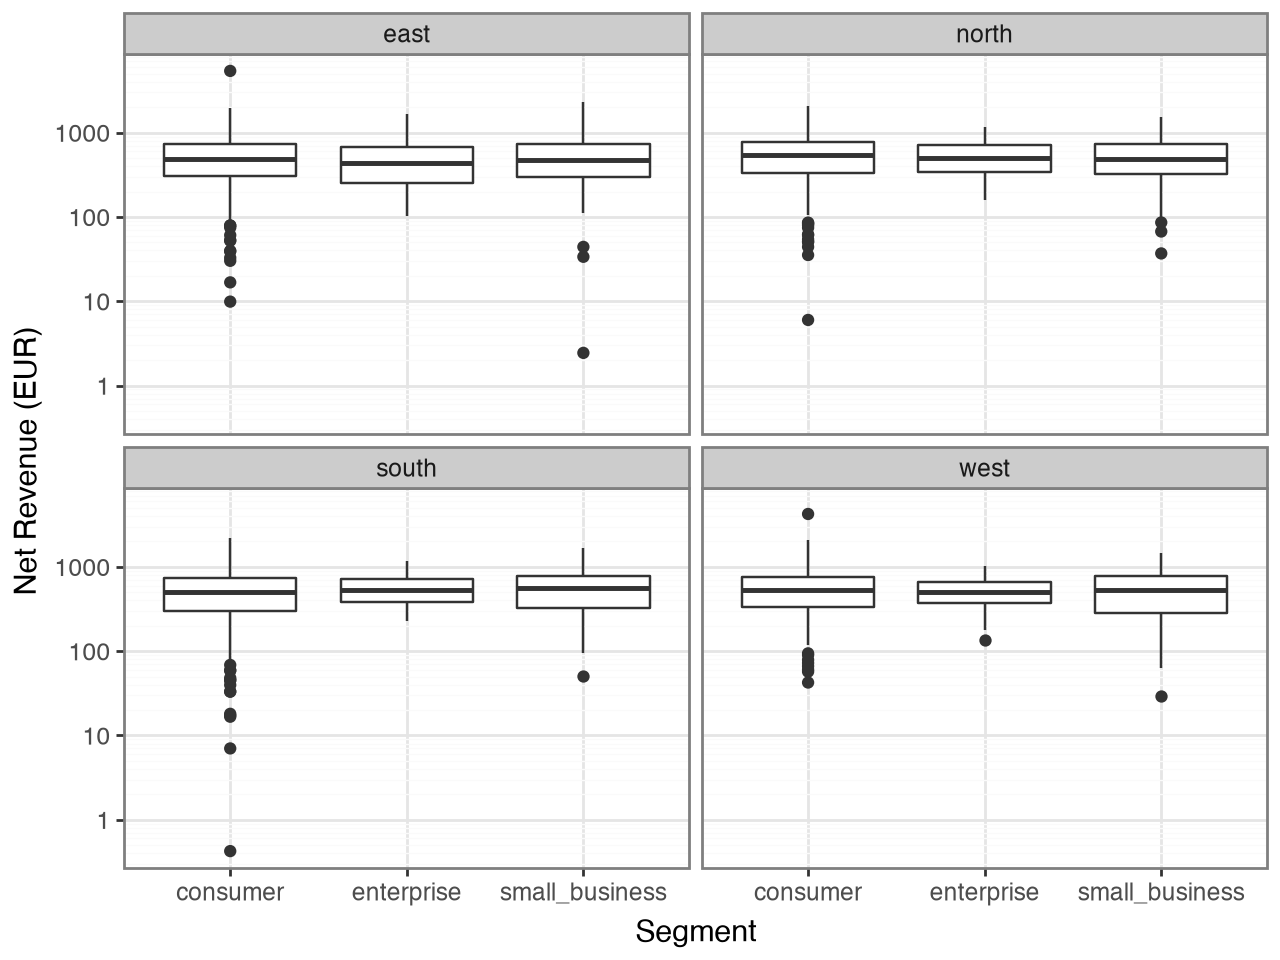

In [110]:
(
    ggplot(analysis_df, aes(y = "net_revenue_eur", x = "segment")) 
    + geom_boxplot()
    + facet_wrap("region")
    + scale_y_log10(name = "Net Revenue (EUR)")
    + scale_x_discrete(name = "Segment")
    + theme_bw()
)

## Task 9 — Answer the question and limit the claim (7 minutes)

Compare `net_revenue_eur` for customers who did and did not opt into marketing. Produce a summary containing, for each opt-in group:

- number of customers;
- mean net revenue;
- median net revenue; and
- interquartile range.

Then write a three-sentence stakeholder summary:

1. State the main numerical difference, with units.
2. Mention distribution shape or mean-versus-median behavior.
3. Explain why this observational comparison does **not** establish that marketing opt-in causes higher or lower revenue.

Also name one way the missing-value assumptions could affect this result.

In [113]:
analysis_df["marketing_opt_in"].sum()
# 1144 of 2000 customers opted in for marketing, that is about 50%.

np.int64(1144)

In [119]:
analysis_df.groupby("marketing_opt_in").agg(
    number_ofP_customers = ("customer_id", "count"),
    mean_net_revenue = ("net_revenue_eur", "mean"),
    median_net_revenue = ("net_revenue_eur", "median"),
    quantile_25_net_revenue = ("net_revenue_eur", lambda x: x.quantile(0.25)),
    quantile_75_net_revenue = ("net_revenue_eur", lambda x: x.quantile(0.75))

)

,number_ofP_customers,mean_net_revenue,median_net_revenue,quantile_25_net_revenue,quantile_75_net_revenue
marketing_opt_in,,,,,
False,856,555.939346,503.19175,309.071875,739.208750
True,1144,558.861449,501.32000,307.640375,747.640625


Slightly more customers opted in on marketing, but there mean and median ne revenue seams only marginally differnet. but the qunatile range shows that the spread of net revenue is larger in customers that opted in on marketing.

## Retrieval practice — Task 10: select, filter, and sort from memory (5 minutes)

Without copying an earlier chain, use `transactions_clean` to return the 10 largest non-returned transactions on or after `2025-01-01`. Show exactly these columns, in this order:

`transaction_id`, `customer_id`, `transaction_date`, `category`, `net_amount_eur`

Acceptance criteria: exactly 10 rows, descending `net_amount_eur`, no returned transactions, and no dates before the cutoff. Add one compact assertion for one of those criteria.

## Professional reasoning questions

Answer briefly in your own words. You can add a markdown cell below this one.

1. Why would joining raw transactions to customers and then taking the mean transaction amount answer a different question from comparing total customer revenue?
2. What could go wrong if a many-to-many join unexpectedly passes unnoticed? Name one numerical check that would catch it.
3. Why retain a missingness indicator after imputing a value? When could that indicator itself become problematic in predictive modeling?
4. Which additional data or design would you need before making a causal claim about marketing opt-in and revenue?

## Self-check and reflection

Add a markdown cell and record:

- Confidence from 1–5
- The hardest point
- One thing you can now explain clearly
- One operation that deserves repetition
- Whether the 60-minute workload felt too light, about right, or too heavy

## Optional extension — Build a monthly customer panel (outside the 60 minutes)

Create one row per `customer_id` and `transaction_month` with transaction count, signed revenue, and return rate. Then determine whether every customer-month between signup and the analysis date is represented. Explain the difference between a month with zero transactions and a month absent from the table.

This is preparation for longitudinal and time-series work.

## Finish line

The core session is complete when Tasks 1–10 run from a fresh kernel, the assertions pass, and you have written the stakeholder summary and reflection. Ask for a review when you want feedback; the notebook intentionally contains no solutions.